# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer:


**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer:


**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer:


## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
fitness_df = pd.read_csv("data/bodyPerformance.csv")


In [4]:
fitness_df.head()


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [5]:
fitness_df.tail()


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
13388,25.0,M,172.1,71.8,16.2,74.0,141.0,35.8,17.4,47.0,198.0,C
13389,21.0,M,179.7,63.9,12.1,74.0,128.0,33.0,1.1,48.0,167.0,D
13390,39.0,M,177.2,80.5,20.1,78.0,132.0,63.5,16.4,45.0,229.0,A
13391,64.0,F,146.1,57.7,40.4,68.0,121.0,19.3,9.2,0.0,75.0,D
13392,34.0,M,164.0,66.1,19.5,82.0,150.0,35.9,7.1,51.0,180.0,C


In [6]:
fitness_df.shape


(13393, 12)

In [7]:
fitness_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  float64
 1   gender                   13393 non-null  str    
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  str    
dtypes: float64(10), str(2)
memory usage: 1.3 MB


In [8]:
fitness_df.isna().sum()


age                        0
gender                     0
height_cm                  0
weight_kg                  0
body fat_%                 0
diastolic                  0
systolic                   0
gripForce                  0
sit and bend forward_cm    0
sit-ups counts             0
broad jump_cm              0
class                      0
dtype: int64

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
|  |  |  |  |  |


**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer:I will use recorded gender (M and F) as the categorical grouping feature. The three quantitative features are height_cm (height in centimeters), weight_kg (weight in kilograms), and broad jump_cm (standing broad-jump distance in centimeters). These are distinct measurements whose distributions can be compared across the two groups. No unit conversions are needed. I will inspect missing values and unusual measurements before deciding whether any exclusions are justified, and preserve the original records.


## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does the distribution of height, measured in centimeters, differ between the M and F groups in the Body Performance dataset?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I predict the M group will have a higher median height, but the two distributions will overlap because individuals within each group vary in height. I am less certain whether the groups will differ in spread.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will compare height_cm, measured in centimeters, between the recorded gender categories F and M. Each analyzed row represents one fitness-test record. I will exclude records missing either selected feature or containing a gender code outside F and M, and report the usable group counts. No unit conversion is needed. Unusual heights will be checked rather than automatically removed.


In [9]:
height_df = fitness_df.loc[
    fitness_df["gender"].isin(["F", "M"]),
    ["gender", "height_cm"]
].dropna().copy()

height_df.head()


,gender,height_cm
0,M,172.3
1,M,165.0
2,M,179.6
3,M,174.5
4,M,173.8


In [10]:
height_df["gender"].value_counts().reindex(["F", "M"])


gender
F    4926
M    8467
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


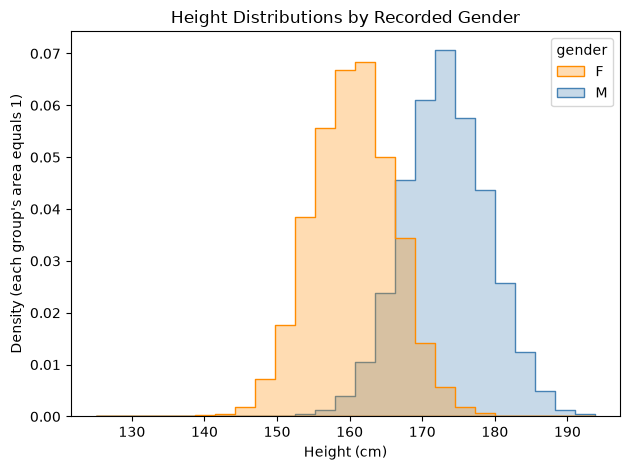

In [11]:
group_colors = {"F": "darkorange", "M": "steelblue"}

sns.histplot(
    data=height_df,
    x="height_cm",
    hue="gender",
    hue_order=["F", "M"],
    palette=group_colors,
    bins=25,
    common_bins=True,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.3
)

plt.title("Height Distributions by Recorded Gender")
plt.xlabel("Height (cm)")
plt.ylabel("Density (each group's area equals 1)")
plt.tight_layout()
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:


In [12]:
height_summary = height_df.groupby("gender")["height_cm"].describe()
height_summary["IQR"] = height_summary["75%"] - height_summary["25%"]
height_summary


,count,mean,std,min,25%,50%,75%,max,IQR
gender,,,,,,,,,
F,4926.0,160.485404,5.648771,125.0,156.6,160.5,164.3,179.0,7.7
M,8467.0,173.257399,5.810007,145.8,169.3,173.1,177.1,193.8,7.8


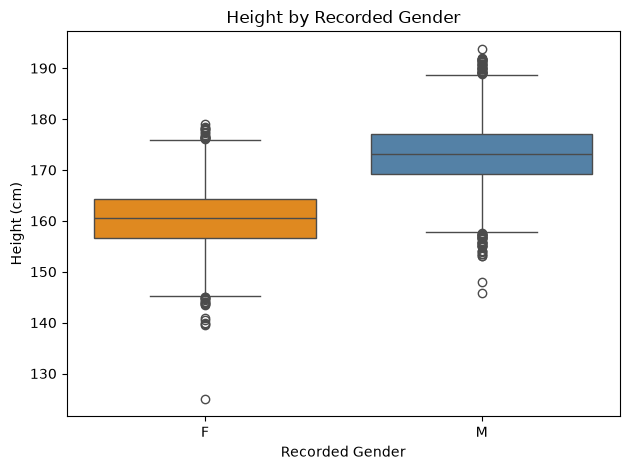

In [13]:
sns.boxplot(
    data=height_df,
    x="gender",
    y="height_cm",
    order=["F", "M"],
    hue="gender",
    palette=group_colors,
    dodge=False
)

plt.title("Height by Recorded Gender")
plt.xlabel("Recorded Gender")
plt.ylabel("Height (cm)")
plt.tight_layout()
plt.show()


In [15]:
height_summary[["count", "mean", "50%", "25%", "75%", "IQR"]].round(2)

,count,mean,50%,25%,75%,IQR
gender,,,,,,
F,4926.0,160.49,160.5,156.6,164.3,7.7
M,8467.0,173.26,173.1,169.3,177.1,7.8


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The calculated centers are close to my visual estimates. The F group has a median height of 160.5 cm and a mean of 160.49 cm; the M group has a median of 173.1 cm and a mean of 173.26 cm. The M median is 12.6 cm higher. The middle 50% spans 156.6–164.3 cm for F and 169.3–177.1 cm for M, giving similar IQRs of 7.7 and 7.8 cm. Although these middle intervals do not overlap, the full distributions do. The histogram reveals shape and overlap, while the box plot summarizes medians, middle spreads, and potential outliers but hides detailed distribution shapes.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [14]:
display(
    fitness_df.loc[
        fitness_df["gender"].isin(["F", "M"])
    ].sort_values("height_cm").head(5)
)

display(
    fitness_df.loc[
        fitness_df["gender"].isin(["F", "M"])
    ].sort_values("height_cm").tail(5)
)

print("Zero or negative heights:", (height_df["height_cm"] <= 0).sum())

display(pd.DataFrame({
    "Usable records": height_df.groupby("gender").size(),
    "Summary count": height_summary["count"]
}))


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
8251,56.0,F,125.0,34.40,39.2,69.0,125.0,12.6,17.0,27.0,109.0,B
6882,56.0,F,139.5,44.80,32.3,81.0,133.0,20.8,21.1,5.0,100.0,D
2235,53.0,F,139.8,64.72,42.9,80.0,139.0,23.6,7.8,7.0,125.0,D
6057,28.0,F,139.9,52.20,44.8,79.0,132.0,14.1,-5.2,0.0,113.0,D
11237,64.0,F,140.5,49.60,32.1,71.0,116.0,22.4,25.3,19.0,152.0,A


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
4961,26.0,M,191.8,101.4,24.9,86.0,120.0,65.1,20.2,59.0,247.0,A
13096,48.0,M,191.8,87.5,19.7,67.0,110.0,42.1,-12.0,20.0,160.0,D
4681,22.0,M,191.9,92.8,24.8,87.0,136.0,42.0,-11.2,41.0,220.0,D
4978,30.0,M,192.0,99.5,26.9,73.0,135.0,50.5,-8.2,41.0,138.0,D
5386,30.0,M,193.8,93.4,19.4,77.0,133.0,52.5,11.0,54.0,230.0,C


Zero or negative heights: 0


,Usable records,Summary count
gender,,
F,4926,4926.0
M,8467,8467.0


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I would be suspicious of zero or negative heights, incorrect units, or group counts that disagree with the summaries. No zero or negative heights were found, and the usable counts matched the summary counts: 4,926 for F and 8,467 for M. The inspected heights ranged from 125.0 to 193.8 cm, consistent with the plots. The 125.0 cm record is unusually low, but I cannot determine from this file alone whether it is an error. I retained the extreme observations rather than removing them simply because they appear as outliers. No corrections were made, and the accuracy of unusual measurements remains uncertain.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: Among the 4,926 F and 8,467 M records analyzed, the M group’s height distribution was centered higher: its median was 173.1 cm compared with 160.5 cm for F. The groups had similar middle spreads, with IQRs of 7.8 cm and 7.7 cm, respectively. Their distributions overlapped, so group membership does not determine an individual’s height.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: A reader should not conclude that every M participant is taller than every F participant, because the height distributions overlap. These records are not established as representative of the general population, and differences in age or participant selection may affect the comparison. Unusually low or high measurements remain uncertain without further verification. This descriptive comparison does not establish causation.


## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does the distribution of weight, measured in kilograms, differ between the recorded F and M groups in the Body Performance dataset?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I predict the M group will have a higher median weight, with considerable overlap between the groups. I expect some high-weight observations to create a longer right tail, but I am uncertain which group will have greater spread.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:


In [16]:
weight_df = fitness_df.loc[
    fitness_df["gender"].isin(["F", "M"]),
    ["gender", "weight_kg"]
].dropna().copy()

weight_df.head()


,gender,weight_kg
0,M,75.24
1,M,55.80
2,M,78.00
3,M,71.10
4,M,67.70


In [17]:
weight_df["gender"].value_counts().reindex(["F", "M"])


gender
F    4926
M    8467
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


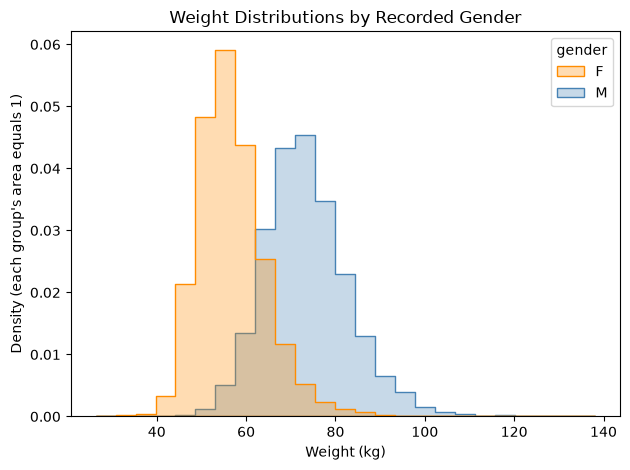

In [18]:
sns.histplot(
    data=weight_df,
    x="weight_kg",
    hue="gender",
    hue_order=["F", "M"],
    palette=group_colors,
    bins=25,
    common_bins=True,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.3
)

plt.title("Weight Distributions by Recorded Gender")
plt.xlabel("Weight (kg)")
plt.ylabel("Density (each group's area equals 1)")
plt.tight_layout()
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: The F group appears centered around 55 kg, with most weights roughly between 45 and 70 kg. The M group appears centered around 72 kg, with most weights roughly between 55 and 90 kg. Both distributions have a longer right tail, and the M group appears more spread out. The groups overlap substantially around 55–75 kg. A few unusually high weights warrant inspection. There are 4,926 F records and 8,467 M records, but each histogram is normalized separately, allowing comparison of distribution shapes despite unequal group sizes.


In [19]:
weight_summary = weight_df.groupby("gender")["weight_kg"].describe()
weight_summary["IQR"] = weight_summary["75%"] - weight_summary["25%"]
weight_summary.round(2)


,count,mean,std,min,25%,50%,75%,max,IQR
gender,,,,,,,,,
F,4926.0,56.91,7.64,26.3,51.96,55.9,61.0,113.3,9.03
M,8467.0,73.58,9.47,36.5,67.30,72.8,79.0,138.1,11.70


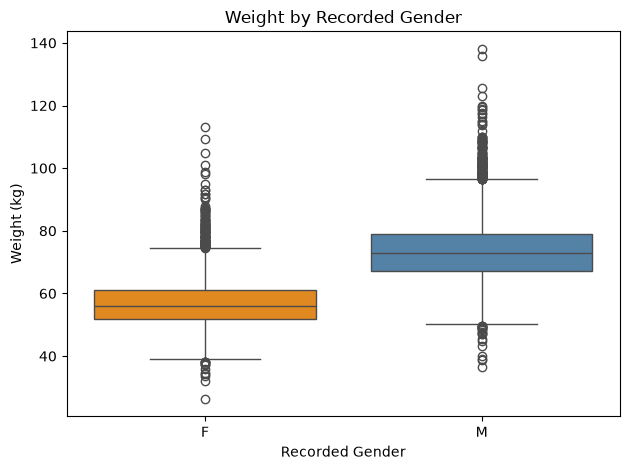

In [20]:
sns.boxplot(
    data=weight_df,
    x="gender",
    y="weight_kg",
    order=["F", "M"],
    hue="gender",
    palette=group_colors,
    dodge=False
)

plt.title("Weight by Recorded Gender")
plt.xlabel("Recorded Gender")
plt.ylabel("Weight (kg)")
plt.tight_layout()
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The summaries support my visual estimates. The F group has a median weight of 55.9 kg and a mean of 56.91 kg, while the M group has a median of 72.8 kg and a mean of 73.58 kg. The M median is 16.9 kg higher. The middle 50% spans approximately 51.96–61.00 kg for F and 67.30–79.00 kg for M, with IQRs of 9.03 kg and 11.70 kg. Thus, M has greater middle spread. Although the middle intervals do not overlap, the full distributions overlap. Means above medians and extended upper tails are consistent with right skew. The histogram shows shape and overlap; the box plot emphasizes medians, IQRs, and potential outliers while hiding detailed shape.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [21]:
display(fitness_df.sort_values("weight_kg").head(5))
display(fitness_df.sort_values("weight_kg").tail(5))

print("Zero or negative weights:", (weight_df["weight_kg"] <= 0).sum())

display(pd.DataFrame({
    "Usable records": weight_df.groupby("gender").size(),
    "Summary count": weight_summary["count"]
}))


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
4370,63.0,F,153.9,26.3,37.0,73.0,120.0,27.2,7.8,0.0,105.0,D
7550,21.0,F,163.7,31.9,31.9,64.0,110.0,27.7,24.8,42.0,149.0,B
7944,45.0,F,153.4,33.7,16.1,81.0,124.0,6.7,11.5,8.0,0.0,D
8251,56.0,F,125.0,34.4,39.2,69.0,125.0,12.6,17.0,27.0,109.0,B
10295,26.0,F,164.8,34.5,34.5,85.0,137.0,2.1,31.0,38.0,175.0,A


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
4995,23.0,M,175.9,119.80,41.7,98.0,152.0,48.4,17.4,56.0,213.0,D
12566,22.0,M,181.2,123.00,42.7,82.0,123.0,41.6,5.0,36.0,177.0,D
554,35.0,M,191.6,125.70,35.2,85.0,156.0,58.0,9.2,52.0,228.0,D
9444,22.0,M,186.2,135.78,35.2,69.0,141.0,49.7,0.1,26.0,216.0,D
11145,30.0,M,190.6,138.10,30.3,82.0,131.0,52.3,4.3,30.0,181.0,D


Zero or negative weights: 0


,Usable records,Summary count
gender,,
F,4926,4926.0
M,8467,8467.0


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I would be suspicious of zero or negative weights, incorrect units, or mismatched group counts. No nonpositive weights were found, and the counts matched: 4,926 F records and 8,467 M records. The original records ranged from 26.3 to 138.1 kg, matching the summary and plots. Some low values, such as 26.3 kg at a recorded height of 153.9 cm, deserve verification. I cannot confirm their accuracy from this file alone, so I retained them and made no corrections. Points beyond the box-plot whiskers are not automatically recording errors.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: In the analyzed dataset, the 8,467 M records had a higher median weight of 72.8 kg than the 4,926 F records, whose median was 55.9 kg. The difference was 16.9 kg. The M group also had a larger IQR, 11.70 kg compared with 9.03 kg for F. Both distributions had upper tails and overlapping weight ranges, so the group difference does not describe every individual.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: These results should not be generalized automatically to the wider population or interpreted as showing that recorded gender alone determines weight. Height, age, body composition, and participant selection may affect the comparison. Weight alone does not establish a person’s health or fitness. Some extreme measurements remain unverified, and overlapping distributions limit conclusions about individuals.


## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does the distribution of standing broad-jump distance, measured in centimeters, differ between the recorded F and M groups in the Body Performance dataset?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I predict the M group will have a higher median broad-jump distance, but the distributions will overlap because performance varies within each group. I am uncertain which group will have greater spread


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will use gender and broad jump_cm. Each analyzed row represents one fitness-test record, and jump distance is measured in centimeters. I will compare the recorded F and M groups, excluding records missing either selected feature or having a gender code outside these groups. No unit conversion is needed. I will preserve the original records and inspect zero, negative, or unusually large distances before deciding whether any exclusion is justified.


In [22]:
jump_df = fitness_df.loc[
    fitness_df["gender"].isin(["F", "M"]),
    ["gender", "broad jump_cm"]
].dropna().copy()

jump_df.head()


,gender,broad jump_cm
0,M,217.0
1,M,229.0
2,M,181.0
3,M,219.0
4,M,217.0


In [23]:
jump_df["gender"].value_counts().reindex(["F", "M"])


gender
F    4926
M    8467
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


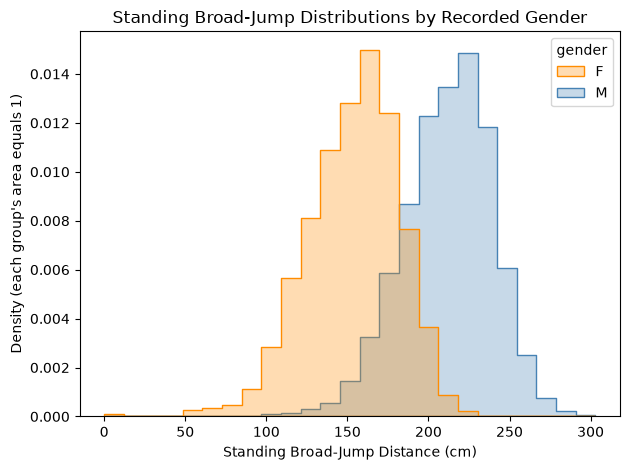

In [24]:
sns.histplot(
    data=jump_df,
    x="broad jump_cm",
    hue="gender",
    hue_order=["F", "M"],
    palette=group_colors,
    bins=25,
    common_bins=True,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.3
)

plt.title("Standing Broad-Jump Distributions by Recorded Gender")
plt.xlabel("Standing Broad-Jump Distance (cm)")
plt.ylabel("Density (each group's area equals 1)")
plt.tight_layout()
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: The F group appears centered around 155–165 cm, with most distances roughly between 110 and 195 cm. The M group appears centered around 210–225 cm, with most distances roughly between 170 and 255 cm. Both distributions have one main peak and longer tails toward shorter distances. They overlap substantially around 150–210 cm. Very short distances, including values near zero, warrant inspection. There are 4,926 F records and 8,467 M records; separate density normalization allows comparison of shapes despite unequal group sizes.


In [25]:
jump_summary = jump_df.groupby("gender")["broad jump_cm"].describe()
jump_summary["IQR"] = jump_summary["75%"] - jump_summary["25%"]
jump_summary.round(2)


,count,mean,std,min,25%,50%,75%,max,IQR
gender,,,,,,,,,
F,4926.0,153.33,28.38,0.0,135.0,156.0,173.0,260.0,38.0
M,8467.0,211.54,28.27,0.0,194.0,214.0,231.0,303.0,37.0


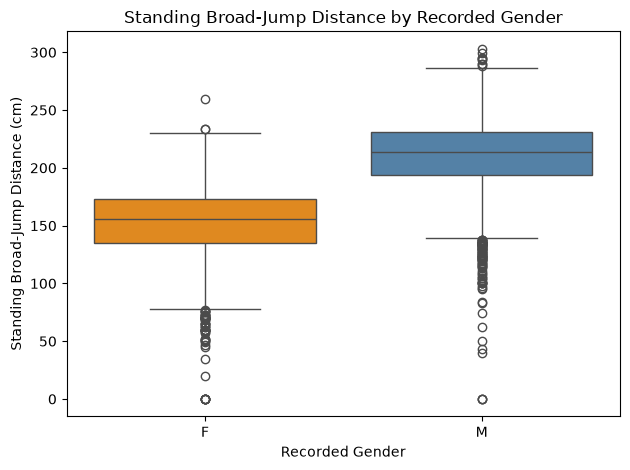

In [26]:
sns.boxplot(
    data=jump_df,
    x="gender",
    y="broad jump_cm",
    order=["F", "M"],
    hue="gender",
    palette=group_colors,
    dodge=False
)

plt.title("Standing Broad-Jump Distance by Recorded Gender")
plt.xlabel("Recorded Gender")
plt.ylabel("Standing Broad-Jump Distance (cm)")
plt.tight_layout()
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The summaries place the F median at 156 cm and the M median at 214 cm, close to my visual estimates. Their means are 153.33 cm and 211.54 cm, respectively. The middle 50% spans 135–173 cm for F and 194–231 cm for M, giving similar IQRs of 38 cm and 37 cm. These middle intervals do not overlap, but the full distributions do. Means below medians and longer lower tails are consistent with left skew. The histogram shows shape and overlap, while the box plot highlights medians, middle spreads, and potential outliers but hides detailed shape.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [27]:
display(
    fitness_df.loc[
        fitness_df["gender"].isin(["F", "M"])
    ].sort_values("broad jump_cm").head(10)
)

display(
    fitness_df.loc[
        fitness_df["gender"].isin(["F", "M"])
    ].sort_values("broad jump_cm").tail(5)
)

print("Negative distances:", (jump_df["broad jump_cm"] < 0).sum())

display(
    jump_df.assign(zero_distance=jump_df["broad jump_cm"].eq(0))
    .groupby("gender")["zero_distance"].sum()
)

display(pd.DataFrame({
    "Usable records": jump_df.groupby("gender").size(),
    "Summary count": jump_summary["count"]
}))


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
7954,61.0,F,153.0,64.6,31.4,77.0,152.0,14.0,20.6,0.0,0.0,D
1919,59.0,F,162.9,61.0,32.6,82.0,123.0,29.7,19.5,0.0,0.0,D
712,58.0,M,168.7,76.1,27.5,84.0,139.0,34.5,2.0,0.0,0.0,D
484,22.0,F,167.4,66.2,34.0,62.0,110.0,28.5,11.2,38.0,0.0,C
7721,56.0,F,156.0,51.1,28.4,73.0,113.0,20.7,23.0,23.0,0.0,C
8599,60.0,F,160.0,76.9,50.3,82.0,141.0,20.1,-8.1,0.0,0.0,D
4756,28.0,M,176.6,82.2,20.7,83.0,126.0,40.9,17.6,46.0,0.0,C
7366,50.0,M,178.2,88.4,23.4,85.0,146.0,54.9,19.3,51.0,0.0,C
4900,60.0,F,162.2,67.3,41.8,47.0,131.0,22.1,19.5,0.0,0.0,D
7944,45.0,F,153.4,33.7,16.1,81.0,124.0,6.7,11.5,8.0,0.0,D


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
8023,22.0,M,178.9,88.60,12.5,84.0,143.0,63.7,18.4,61.0,294.0,A
13024,21.0,M,168.7,61.20,14.1,80.0,142.0,48.7,30.8,48.0,295.0,B
3718,24.0,M,170.1,72.68,21.2,78.0,130.0,39.9,35.2,43.0,295.0,C
5520,26.0,M,180.2,70.96,15.4,86.0,140.0,49.1,16.0,58.0,299.0,A
4496,21.0,M,182.2,78.10,10.7,78.0,136.0,52.0,9.0,67.0,303.0,C


Negative distances: 0


gender
F    7
M    3
Name: zero_distance, dtype: int64

,Usable records,Summary count
gender,,
F,4926,4926.0
M,8467,8467.0


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I would be suspicious of negative jump distances, unclear zero values, incorrect units, or mismatched group counts. No negative distances were found, but there were seven zero distances in F and three in M. I inspected their original records, but these do not establish whether zero represents an unsuccessful attempt, an unperformed test, or a recording issue. I retained the zeros and flagged their meaning as unresolved rather than guessing. The maximum recorded distance was 303 cm. Counts matched the summaries: 4,926 F records and 8,467 M records. No corrections were made.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: The M group’s broad-jump distribution was centered higher, with a median of 214 cm across 8,467 records, compared with 156 cm across 4,926 F records—a difference of 58 cm. Middle spreads were similar: the IQR was 37 cm for M and 38 cm for F. The full distributions overlapped, and both included unusually short distances. These results describe the recorded groups rather than every individual.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:The comparison does not establish that recorded gender causes differences in jumping performance. Age, training, body size, and participant selection may also affect the results. The meaning of the ten zero distances remains uncertain and may affect the lower tails and means. The dataset is not established as representative of the wider population, and overlapping distributions prevent reliable conclusions about an individual from group membership alone.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I used ChatGPT to help select a dataset, explain Python code, interpret charts, and draft written responses. One suggestion I checked was using separately normalized density histograms to compare groups of unequal sizes. I reviewed the code’s common_norm=False setting and the output showing 4,926 F records and 8,467 M records. I accepted this approach because it compares distribution shapes without the larger group automatically having taller bars. I also checked numerical interpretations against the displayed summaries and retained unusual values, including zero jump distances, while documenting their uncertain meaning.


## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
